In [1]:
import pandas as pd

data = pd.read_csv("../data/traffic_clean.csv")

print(data.head())

             date_time     temp  rain_1h  clouds_all  traffic_volume  \
0  2015-06-11 20:00:00  287.586      0.0        92.0          2886.0   
1  2015-06-11 21:00:00      NaN      NaN         NaN             NaN   
2  2015-06-11 22:00:00      NaN      NaN         NaN             NaN   
3  2015-06-11 23:00:00      NaN      NaN         NaN             NaN   
4  2015-06-12 00:00:00      NaN      NaN         NaN             NaN   

      holiday weather_description   temp_f  
0  No Holiday          light rain  57.9848  
1  No Holiday                 NaN      NaN  
2  No Holiday                 NaN      NaN  
3  No Holiday                 NaN      NaN  
4  No Holiday                 NaN      NaN  


In [2]:
# Convert date_time into datetime format
data['date_time'] = pd.to_datetime(data['date_time'])

# Extract the hour of the day (0–23)
data['hour'] = data['date_time'].dt.hour

# Select our five numerical variables
variables = ['temp_f', 'rain_1h', 'clouds_all',
             'hour', 'traffic_volume']

analysis = data[variables].copy()

# Clear names and units for use in graphs (dataset column names remain unchanged)
variable_labels = {
    'temp_f': 'Temperature (°F)',
    'rain_1h': 'Rainfall in One Hour (mm)',
    'clouds_all': 'Cloud Coverage (%)',
    'hour': 'Hour of Day (24-Hour Clock)',
    'traffic_volume': 'Traffic Volume (Vehicles per Hour)'
}

# Short versions fit more clearly on the two heatmaps
heatmap_labels = ['Temp (°F)', 'Rain (mm)', 'Clouds (%)',
                  'Hour (0–23)', 'Traffic (veh/h)']


print(analysis.head())

    temp_f  rain_1h  clouds_all  hour  traffic_volume
0  57.9848      0.0        92.0    20          2886.0
1      NaN      NaN         NaN    21             NaN
2      NaN      NaN         NaN    22             NaN
3      NaN      NaN         NaN    23             NaN
4      NaN      NaN         NaN     0             NaN


In [3]:
# Select rows with complete observations
analysis_valid = analysis.dropna()

# Calculate descriptive statistics
statistics = pd.DataFrame({
    'Mean': analysis_valid.mean(),
    'Median': analysis_valid.median(),
    'Variance': analysis_valid.var(),
    'Std Dev': analysis_valid.std(),
    'Minimum': analysis_valid.min(),
    'Maximum': analysis_valid.max()
})

print(statistics.round(3))

                    Mean   Median     Variance   Std Dev  Minimum   Maximum
temp_f            50.100    54.41      499.988    22.360  -21.568    98.456
rain_1h            0.063     0.00        0.408     0.639    0.000    31.750
clouds_all        41.375    40.00     1526.331    39.068    0.000   100.000
hour              11.484    11.00       48.229     6.945    0.000    23.000
traffic_volume  3299.290  3472.50  3865786.319  1966.160   64.000  7280.000


In [4]:
# Calculate Z-scores for all five variables
z_scores = (analysis_valid - analysis_valid.mean()) / analysis_valid.std()

# Display the first five Z-scores
print(z_scores.head().round(3))

# Count observations with absolute Z-scores greater than 3
outliers = (z_scores.abs() > 3).sum()

print("\nNumber of potential outliers:")
print(outliers)


    temp_f  rain_1h  clouds_all   hour  traffic_volume
0    0.353   -0.098       1.296  1.226          -0.210
22   1.154   -0.098      -1.059  0.938           0.550
24   0.713   -0.098      -0.854  1.226          -0.104
25   0.713   -0.098      -0.854  1.370          -0.000
49   0.937   -0.098       0.886  1.370          -0.132

Number of potential outliers:
temp_f              5
rain_1h           214
clouds_all          0
hour                0
traffic_volume      0
dtype: int64


In [5]:
# Calculate the covariance matrix
cov_matrix = analysis_valid.cov()

# Display the covariance matrix
print(cov_matrix.round(3))

                  temp_f  rain_1h  clouds_all      hour  traffic_volume
temp_f           499.988    1.030     -65.874    22.086        5896.465
rain_1h            1.030    0.408       1.818    -0.022         -16.585
clouds_all       -65.874    1.818    1526.331    20.165        8511.582
hour              22.086   -0.022      20.165    48.229        4895.353
traffic_volume  5896.465  -16.585    8511.582  4895.353     3865786.319


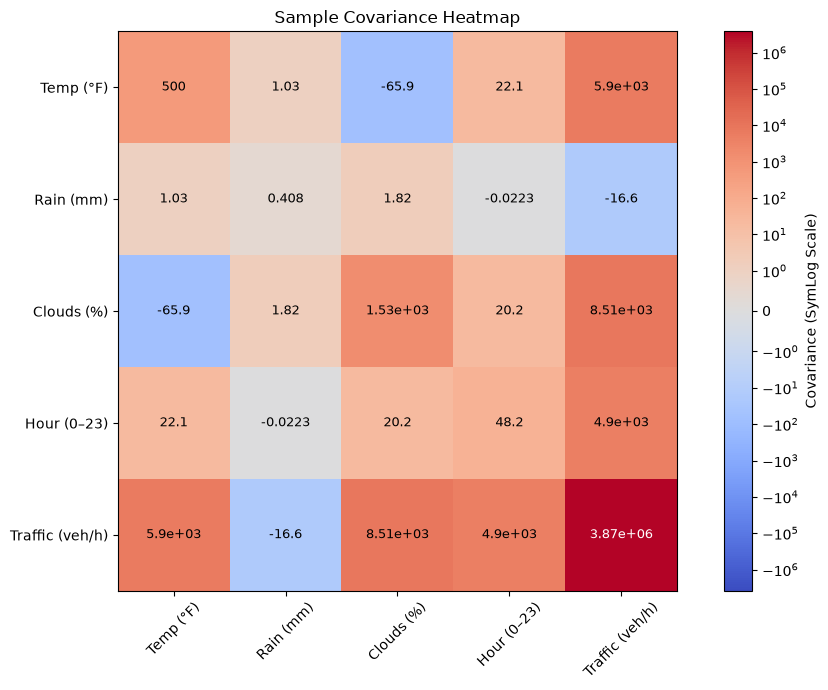

In [6]:

import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm

# Adjust the color scale
limit = abs(cov_matrix).to_numpy().max()

plt.figure(figsize=(10, 7))

plt.imshow(cov_matrix, cmap='coolwarm',
           norm=SymLogNorm(linthresh=1, vmin=-limit, vmax=limit))

plt.colorbar(label='Covariance (SymLog Scale)')

# Label the variables
plt.xticks(range(5), heatmap_labels, rotation=45)
plt.yticks(range(5), heatmap_labels)

# Display covariance values inside each square
for i in range(5):
    for j in range(5):
        value = cov_matrix.iloc[i, j]
        plt.text(j, i, f'{value:.3g}',
                 ha='center', va='center', fontsize=9,
                 color='white' if abs(value) > 100000 else 'black')

plt.title('Sample Covariance Heatmap')
plt.tight_layout()
plt.savefig('../figures/smp_covHM.png', dpi=150)
plt.show()


In [7]:
# Calculate the correlation matrix
corr_matrix = analysis_valid.corr()

# Display the correlation matrix
print(corr_matrix.round(3))

                temp_f  rain_1h  clouds_all   hour  traffic_volume
temp_f           1.000    0.072      -0.075  0.142           0.134
rain_1h          0.072    1.000       0.073 -0.005          -0.013
clouds_all      -0.075    0.073       1.000  0.074           0.111
hour             0.142   -0.005       0.074  1.000           0.359
traffic_volume   0.134   -0.013       0.111  0.359           1.000


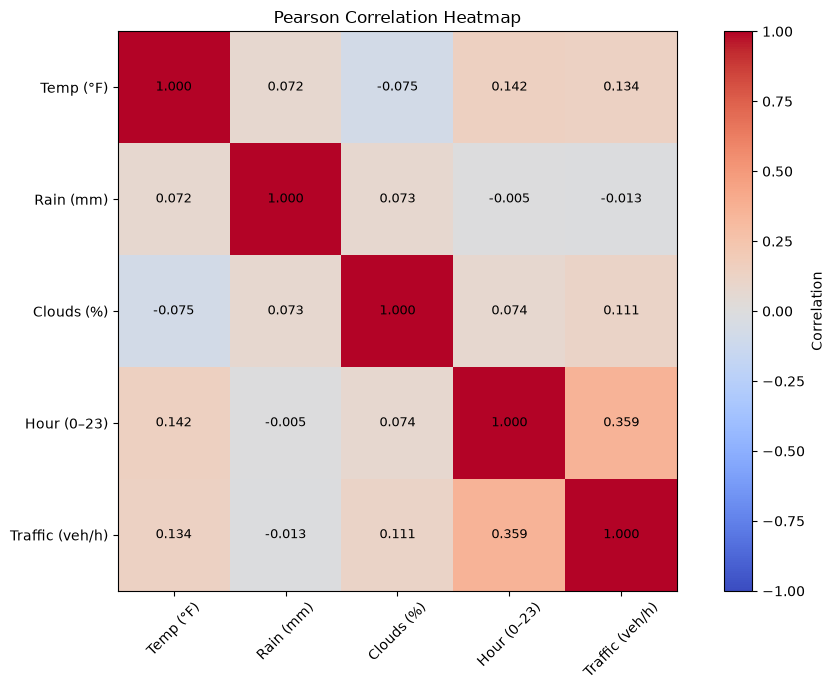

In [8]:

# Create the correlation heatmap
plt.figure(figsize=(10, 7))

plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)

# Add color scale
plt.colorbar(label='Correlation')

# Label the variables
plt.xticks(range(5), heatmap_labels, rotation=45)
plt.yticks(range(5), heatmap_labels)

# Display correlation values inside each square
for i in range(5):
    for j in range(5):
        plt.text(j, i, f'{corr_matrix.iloc[i, j]:.3f}',
                 ha='center', va='center', fontsize=9)

plt.title('Pearson Correlation Heatmap')
plt.tight_layout()
plt.savefig('../figures/corrHM.png', dpi=150)
plt.show()


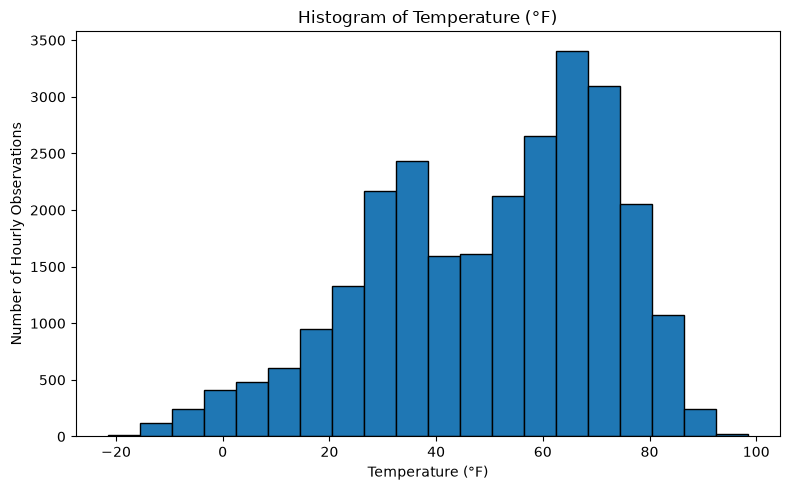

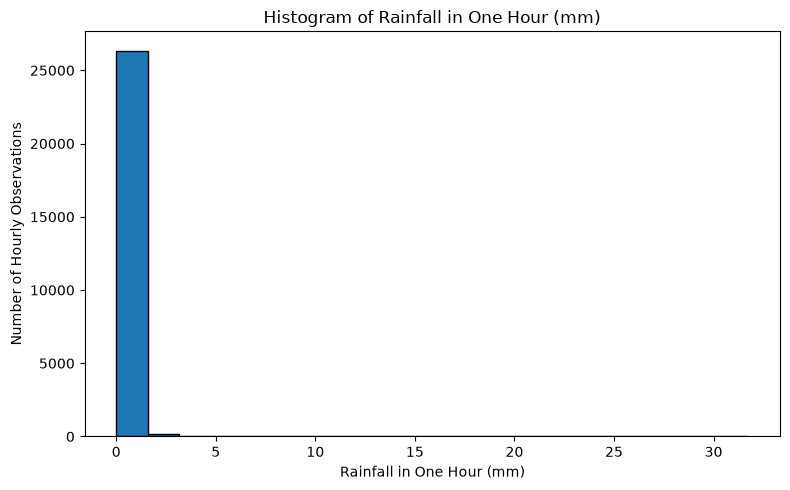

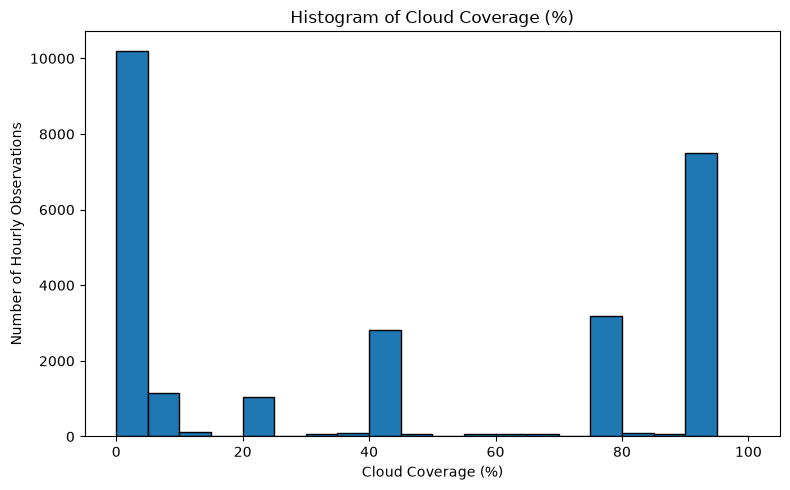

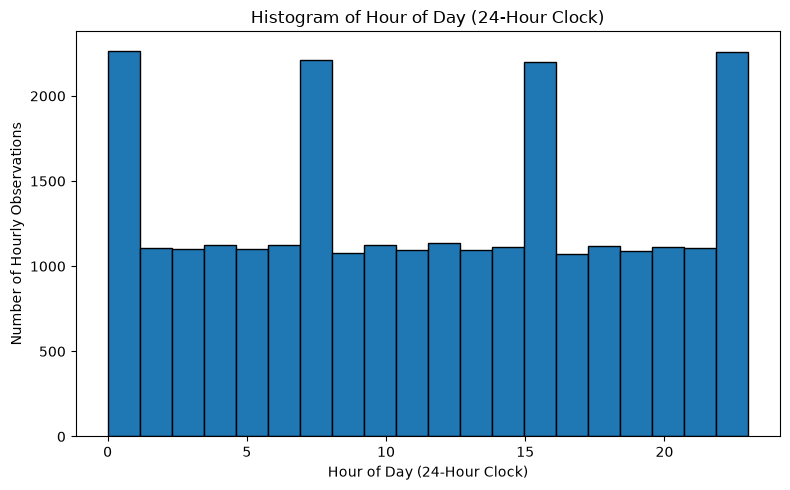

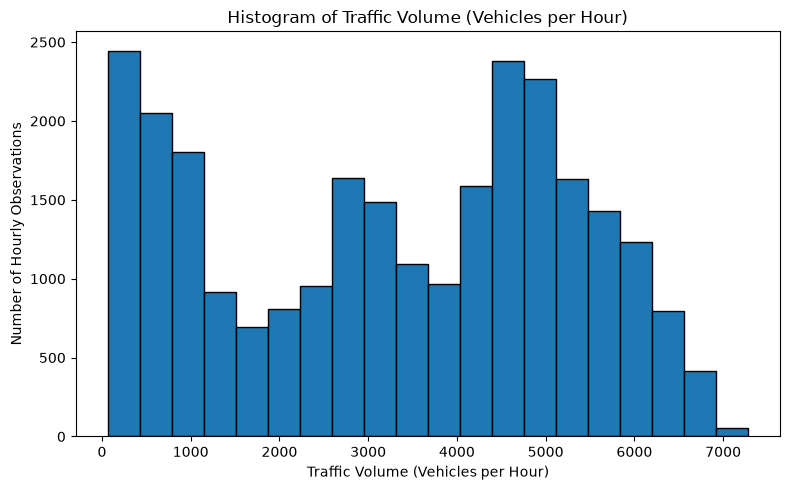

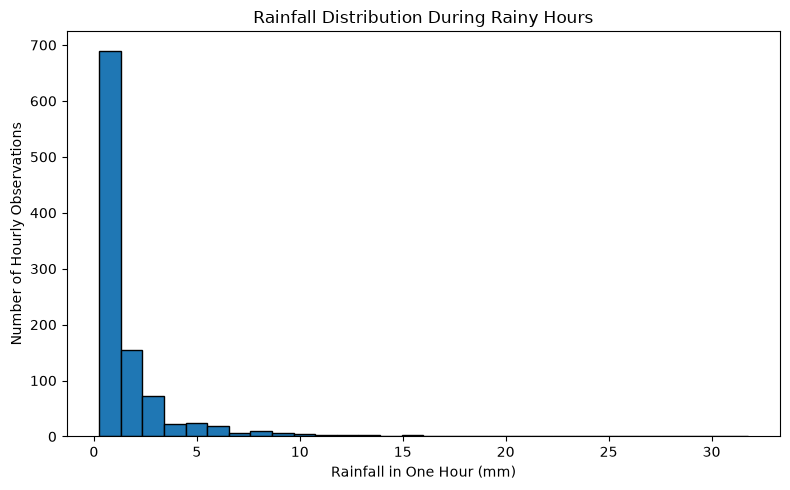

In [9]:

# Create a separate histogram for each variable
for column in variables:
    plt.figure(figsize=(8, 5))

    plt.hist(analysis_valid[column], bins=20, edgecolor='black')

    plt.title(f'Histogram of {variable_labels[column]}')
    plt.xlabel(variable_labels[column])
    plt.ylabel('Number of Hourly Observations')

    plt.tight_layout()
    plt.savefig('../figures/hist.png', dpi=150)
    plt.show()


# Additional histogram showing only rainy hours
rainy_hours = analysis_valid[analysis_valid['rain_1h'] > 0]

plt.figure(figsize=(8, 5))

plt.hist(rainy_hours['rain_1h'], bins=30, edgecolor='black')

plt.title('Rainfall Distribution During Rainy Hours')
plt.xlabel('Rainfall in One Hour (mm)')
plt.ylabel('Number of Hourly Observations')

plt.tight_layout()
plt.savefig('../figures/rainfall-hours.png', dpi=150)
plt.show()



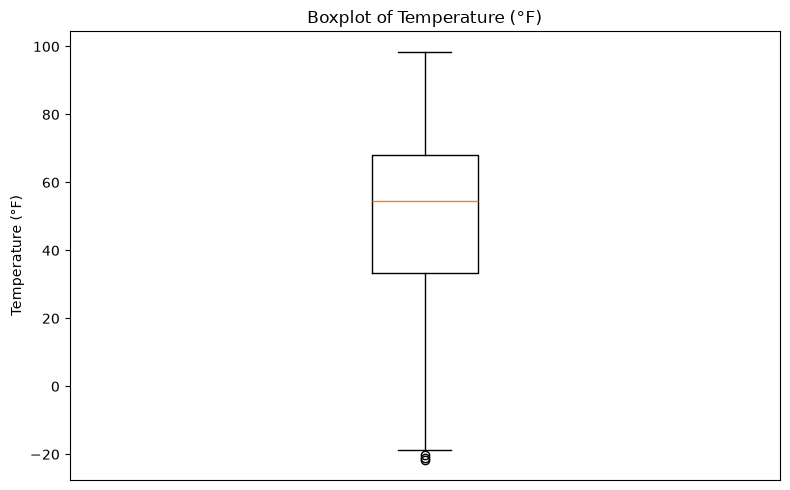

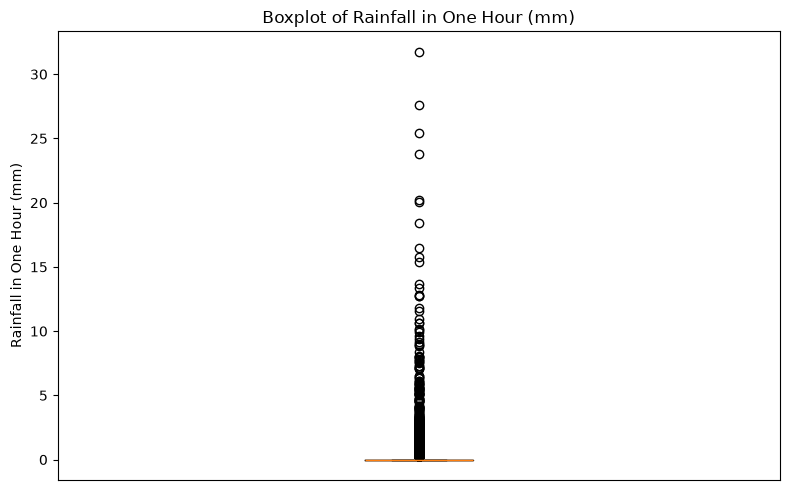

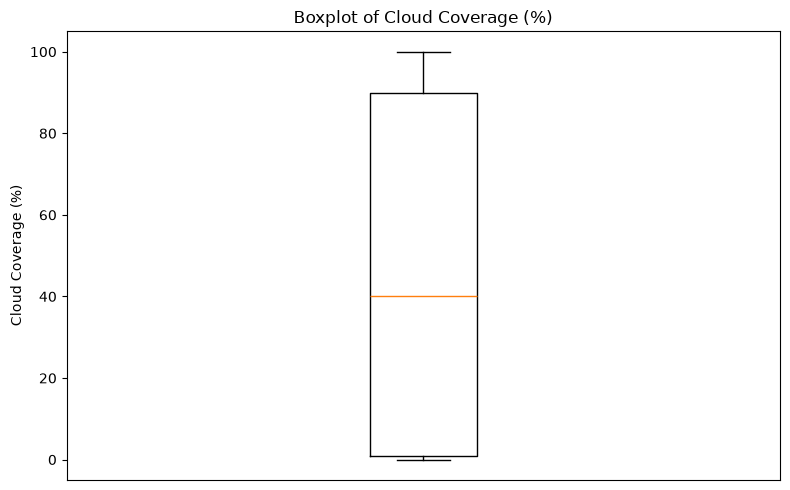

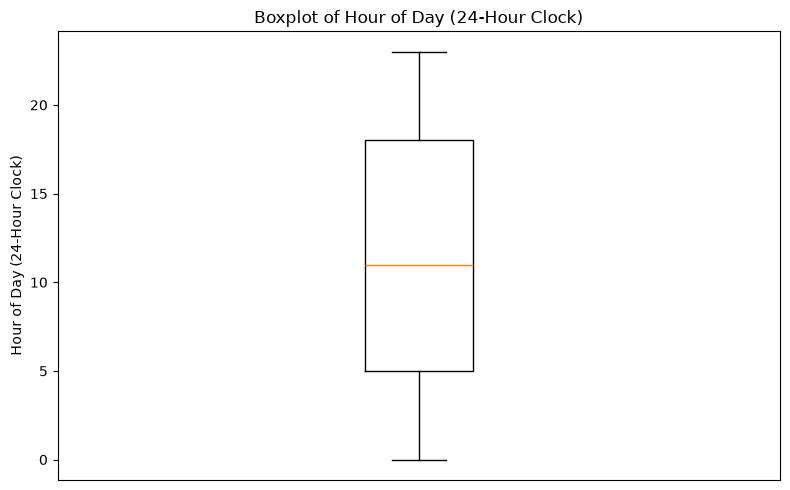

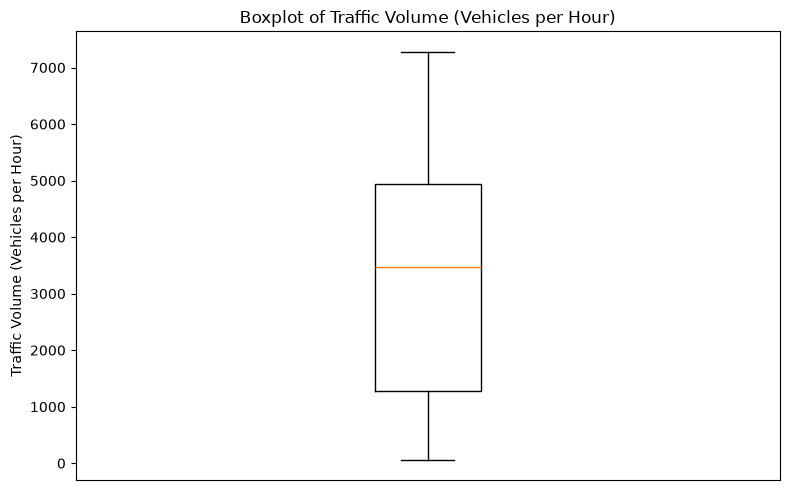

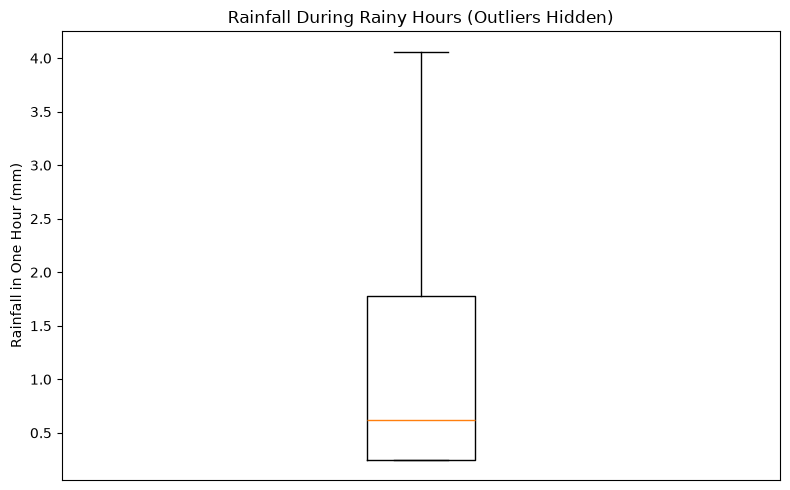

In [10]:


# Create a separate boxplot for each variable
for column in variables:
    plt.figure(figsize=(8, 5))

    plt.boxplot(analysis_valid[column])
    plt.xticks([])  # Only one box; its x-position has no meaning

    plt.title(f'Boxplot of {variable_labels[column]}')
    plt.ylabel(variable_labels[column])

    plt.tight_layout()
    plt.savefig('../figures/bxplt.png', dpi=150)
    plt.show()


# Additional boxplot showing only rainy hours
rainy_rainfall = analysis_valid.loc[
    analysis_valid['rain_1h'] > 0, 'rain_1h'
]

plt.figure(figsize=(8, 5))

plt.boxplot(rainy_rainfall, showfliers=False)
plt.xticks([])  # Only one box; its x-position has no meaning

plt.title('Rainfall During Rainy Hours (Outliers Hidden)')
plt.ylabel('Rainfall in One Hour (mm)')

plt.tight_layout()
plt.savefig('../figures/rainfall.png', dpi=150)
plt.show()


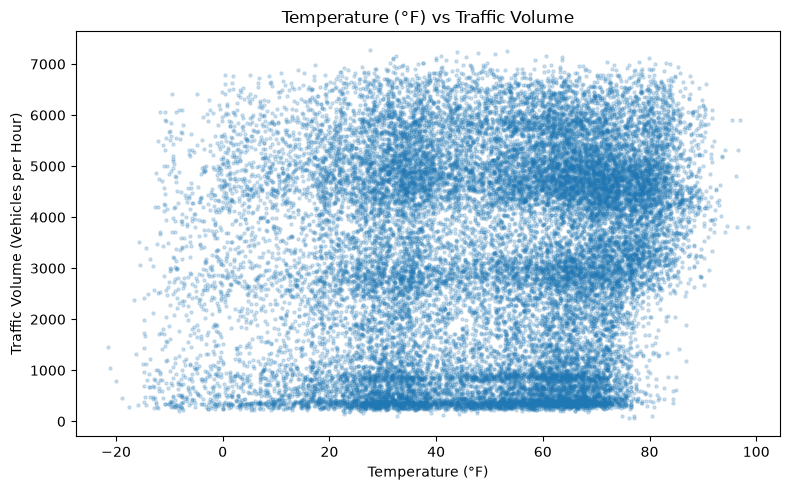

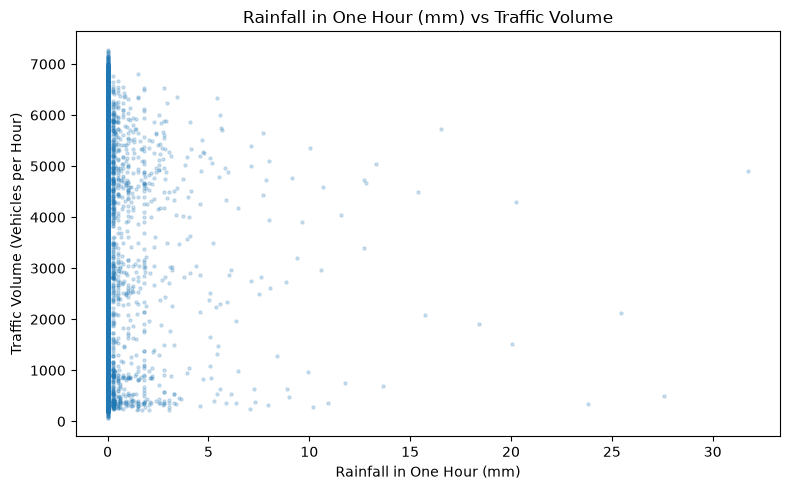

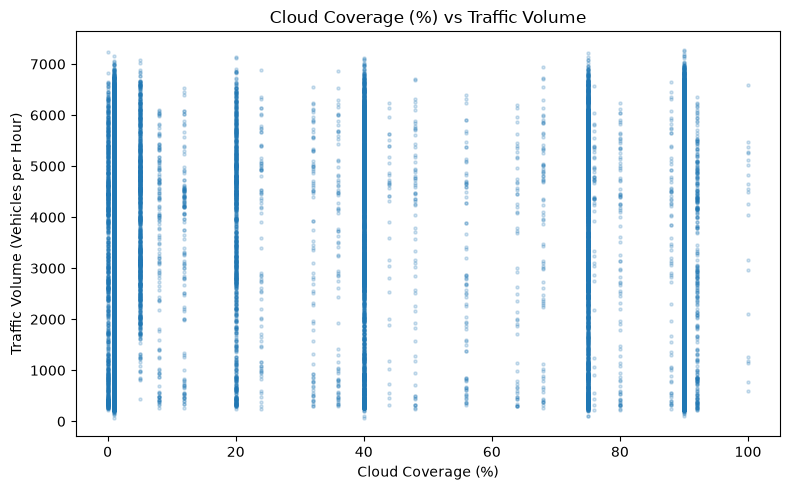

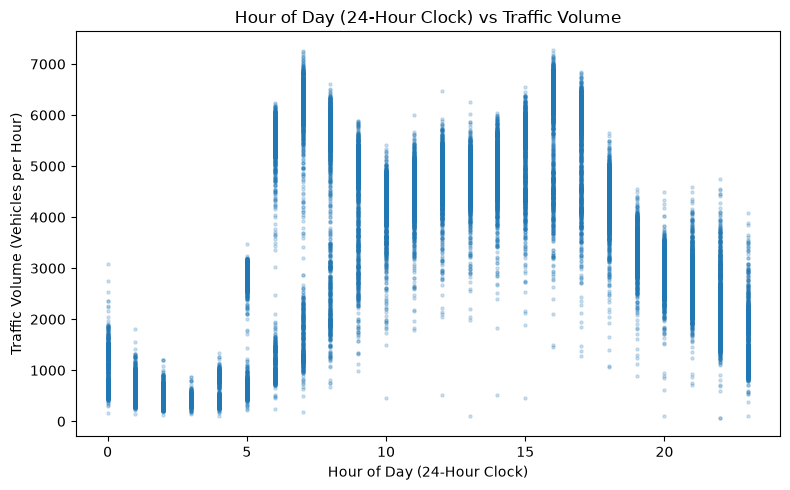

In [11]:

# Variables to compare against traffic volume
x_variables = ['temp_f', 'rain_1h', 'clouds_all', 'hour']

# Create a separate scatterplot for each variable
for column in x_variables:
    plt.figure(figsize=(8, 5))

    plt.scatter(analysis_valid[column],
                analysis_valid['traffic_volume'],
                s=5, alpha=0.2)

    plt.title(f'{variable_labels[column]} vs Traffic Volume')
    plt.xlabel(variable_labels[column])
    plt.ylabel('Traffic Volume (Vehicles per Hour)')

    plt.tight_layout()
    plt.savefig('../figures/trafficvolume.png', dpi=150)
    plt.show()


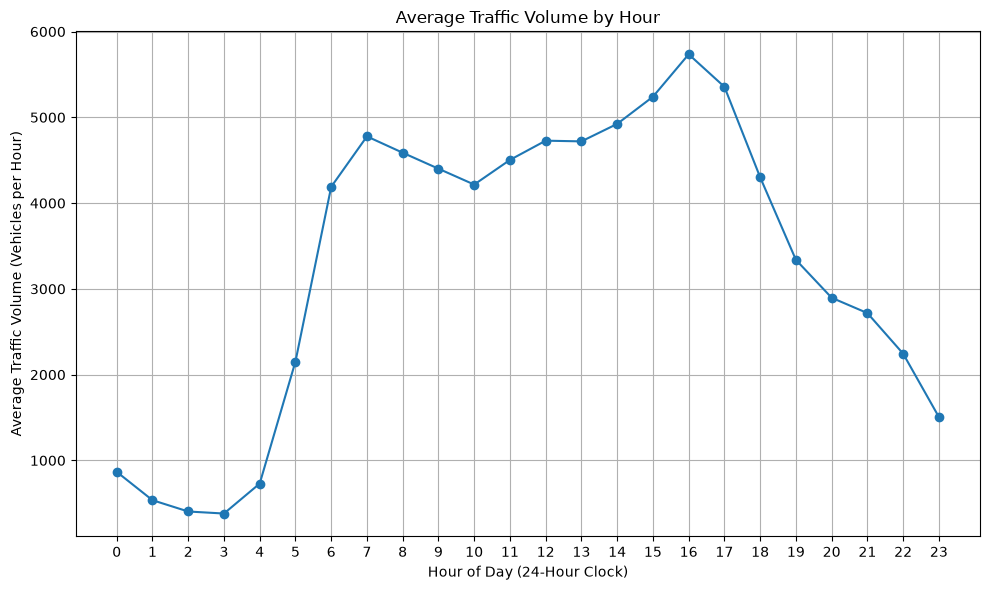

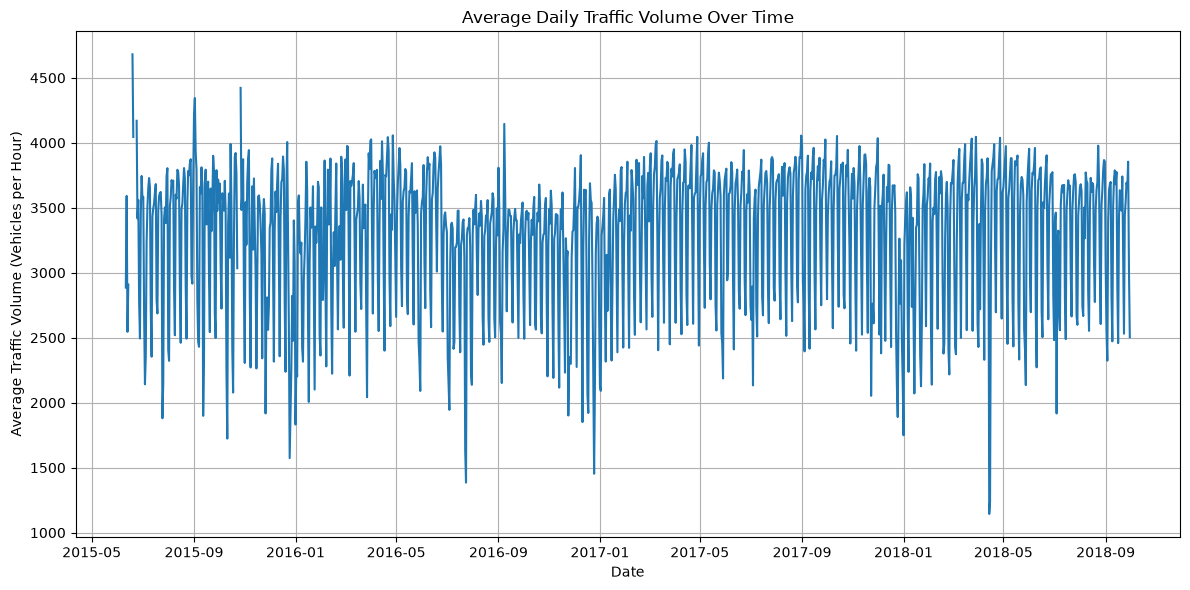

In [12]:

# Calculate average traffic volume for each hour
hourly_traffic = analysis_valid.groupby('hour')['traffic_volume'].mean()

# Create line graph
plt.figure(figsize=(10, 6))

plt.plot(hourly_traffic.index, hourly_traffic.values,
         marker='o')

plt.title('Average Traffic Volume by Hour')
plt.xlabel('Hour of Day (24-Hour Clock)')
plt.ylabel('Average Traffic Volume (Vehicles per Hour)')

plt.xticks(range(0, 24))
plt.grid(True)

plt.tight_layout()
plt.savefig('../figures/avgvol-hour.png', dpi=150)
plt.show()



# Calculate average daily traffic volume
daily_traffic = data.groupby(
    data['date_time'].dt.date
)['traffic_volume'].mean()

# Create daily traffic line graph
plt.figure(figsize=(12, 6))

plt.plot(daily_traffic.index, daily_traffic.values)

plt.title('Average Daily Traffic Volume Over Time')
plt.xlabel('Date')
plt.ylabel('Average Traffic Volume (Vehicles per Hour)')

plt.grid(True)
plt.tight_layout()
plt.savefig('../figures/avgtrafficvol.png', dpi=150)
plt.show()


In [13]:

# Categorical Data Analysis

# Display weather condition frequencies
print("Weather Descriptions:")
print(data['weather_description'].value_counts())

# Display holiday frequencies
print("\nHolidays:")
print(data['holiday'].value_counts())


Weather Descriptions:
weather_description
sky is clear                           9636
overcast clouds                        2748
scattered clouds                       2394
broken clouds                          2392
mist                                   1728
light snow                             1655
light rain                             1599
few clouds                             1033
moderate rain                           842
proximity thunderstorm                  568
haze                                    488
light intensity drizzle                 368
drizzle                                 209
snow                                    195
fog                                     191
heavy intensity rain                    172
thunderstorm                            105
proximity shower rain                    79
proximity thunderstorm with rain         42
thunderstorm with heavy rain             41
heavy snow                               41
thunderstorm with light rain      

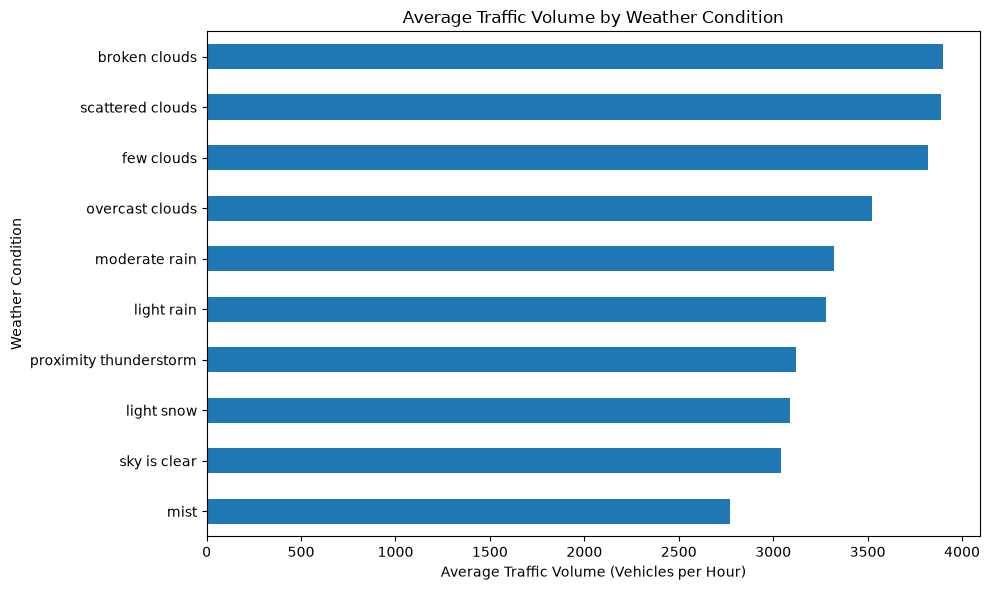

In [14]:

# Select observations with valid weather and traffic data
weather_data = data.dropna(subset=['weather_description', 'traffic_volume'])

# Select the 10 most common weather descriptions
top_weather = weather_data['weather_description'].value_counts().head(10).index

# Calculate average traffic volume for each weather condition
weather_traffic = weather_data[
    weather_data['weather_description'].isin(top_weather)
].groupby('weather_description')['traffic_volume'].mean()

# Create bar chart
plt.figure(figsize=(10, 6))

weather_traffic.sort_values().plot(kind='barh')

plt.title('Average Traffic Volume by Weather Condition')
plt.xlabel('Average Traffic Volume (Vehicles per Hour)')
plt.ylabel('Weather Condition')

plt.tight_layout()
plt.savefig('../figures/trafficweather.png', dpi=150)
plt.show()


holiday_status
Holiday        2623.19
Non-Holiday    3320.07
Name: traffic_volume, dtype: float64

Number of Observations:
holiday_status
Non-Holiday    25840
Holiday          794
Name: count, dtype: int64


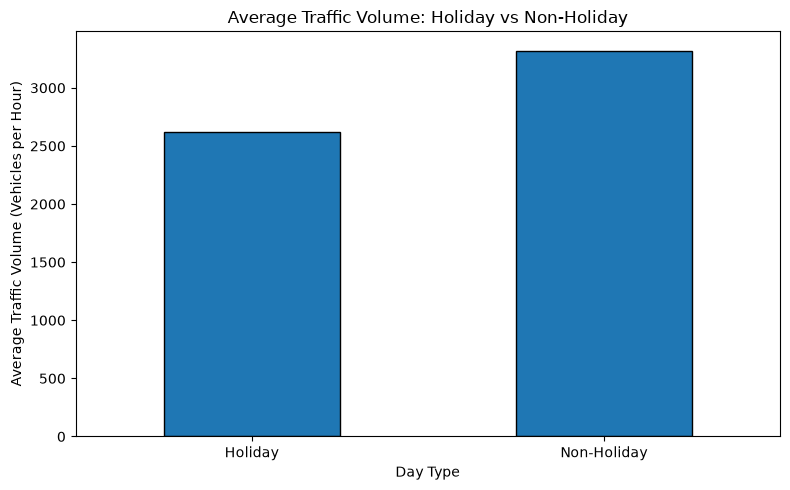

In [15]:

# Select observations with valid traffic data
holiday_data = data.dropna(subset=['traffic_volume']).copy()

# Identify holidays and non-holidays
holiday_data['holiday_status'] = holiday_data['holiday'].apply(
    lambda x: 'Non-Holiday' if x == 'No Holiday' else 'Holiday'
)

# Calculate average traffic volume
holiday_traffic = holiday_data.groupby('holiday_status')['traffic_volume'].mean()

print(holiday_traffic.round(2))

# Display the number of observations
print("\nNumber of Observations:")
print(holiday_data['holiday_status'].value_counts())

# Create bar chart
plt.figure(figsize=(8, 5))

holiday_traffic.plot(kind='bar', edgecolor='black')

plt.title('Average Traffic Volume: Holiday vs Non-Holiday')
plt.xlabel('Day Type')
plt.ylabel('Average Traffic Volume (Vehicles per Hour)')

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../figures/holiday.png', dpi=150)
plt.show()


C:\Users\Alex\AppData\Local\Temp\ipykernel_29660\3046519471.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  rush_data = rush_data[rush_data['date_time'].dt.dayofweek < 5]


Average Traffic Volume:
rush_period          Afternoon  Morning
weather_description                    
sky is clear           5946.08  5621.38
light rain             5883.37  5704.36
moderate rain          5893.06  5740.38
light snow             5536.36  5139.65
mist                   5933.63  5725.22

Number of Observations:
rush_period          Afternoon  Morning
weather_description                    
sky is clear               637      747
light rain                 139      131
moderate rain               68       95
light snow                 134      181
mist                        38      334


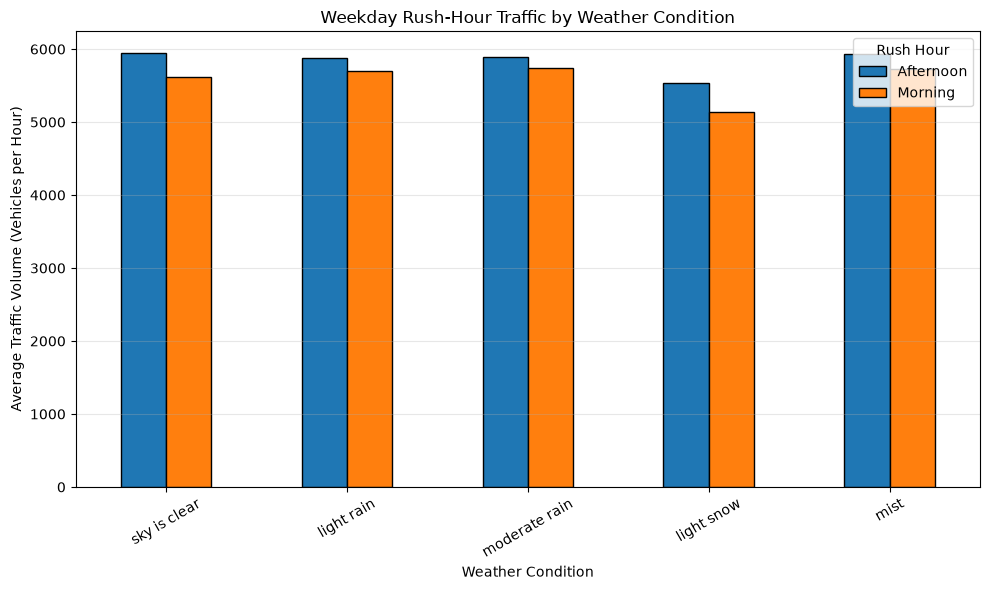

In [16]:

# Select observations with valid weather and traffic data
rush_data = data.dropna(
    subset=['weather_description', 'traffic_volume']
).copy()

# Keep only weekdays (Monday through Friday)
rush_data = rush_data[rush_data['date_time'].dt.dayofweek < 5]

# Extract the hour
rush_data['hour'] = rush_data['date_time'].dt.hour

# Keep morning and afternoon rush hours
rush_data = rush_data[
    rush_data['hour'].between(6, 8) |
    rush_data['hour'].between(15, 17)
].copy()

# Label the two rush-hour periods
rush_data['rush_period'] = rush_data['hour'].apply(
    lambda h: 'Morning' if h < 9 else 'Afternoon'
)

# Select five weather conditions
weather_types = [
    'sky is clear',
    'light rain',
    'moderate rain',
    'light snow',
    'mist'
]

rush_data = rush_data[
    rush_data['weather_description'].isin(weather_types)
]

# Calculate average traffic and observation counts
rush_summary = rush_data.groupby(
    ['weather_description', 'rush_period']
)['traffic_volume'].agg(['mean', 'count'])

# Arrange the results into tables
rush_averages = rush_summary['mean'].unstack().reindex(weather_types)
rush_counts = rush_summary['count'].unstack().reindex(weather_types)

print("Average Traffic Volume:")
print(rush_averages.round(2))

print("\nNumber of Observations:")
print(rush_counts)

# Create grouped bar chart
rush_averages.plot(kind='bar', figsize=(10, 6), edgecolor='black')

plt.title('Weekday Rush-Hour Traffic by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Average Traffic Volume (Vehicles per Hour)')
plt.xticks(rotation=30)
plt.legend(title='Rush Hour')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../figures/rush-hour.png', dpi=150)
plt.show()


C:\Users\Alex\AppData\Local\Temp\ipykernel_29660\82405415.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  weekday_data['day_type'] = weekday_data['date_time'].dt.dayofweek.apply(


OSError: [Errno 22] Invalid argument: '../figures/<name>.png'

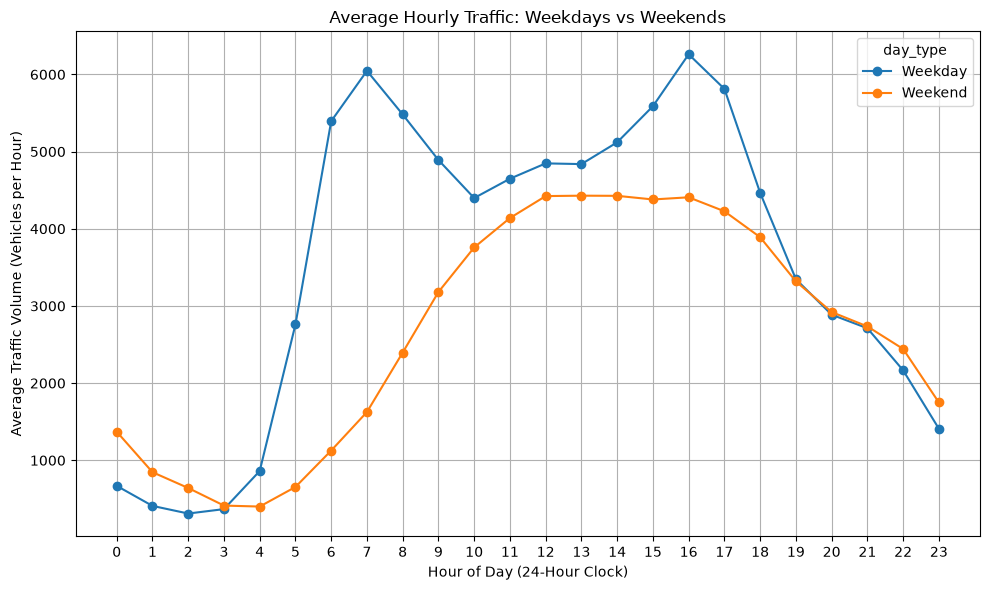

In [17]:

# Select observations with valid traffic data
weekday_data = data.dropna(subset=['traffic_volume']).copy()

# Identify weekdays and weekends
weekday_data['day_type'] = weekday_data['date_time'].dt.dayofweek.apply(
    lambda day: 'Weekend' if day >= 5 else 'Weekday'
)

# Calculate average traffic volume by hour and day type
hourly_comparison = weekday_data.groupby(
    ['hour', 'day_type']
)['traffic_volume'].mean().unstack()

# Create line graph
hourly_comparison.plot(figsize=(10, 6), marker='o')

plt.title('Average Hourly Traffic: Weekdays vs Weekends')
plt.xlabel('Hour of Day (24-Hour Clock)')
plt.ylabel('Average Traffic Volume (Vehicles per Hour)')

plt.xticks(range(0, 24))
plt.grid(True)

plt.tight_layout()
plt.savefig('../figures/<name>.png', dpi=150)
plt.show()
